# UK Biobank Cardiac Motion Analysis with LaMoD

This notebook demonstrates the full LaMoD pipeline using the new cardiac toolkit API:
1. Load UK Biobank cardiac cine MRI data
2. Whole heart detection and preprocessing
3. CarSON segmentation for myocardium
4. **LaMoD motion tracking** (registration + diffusion + decoder)
5. Strain analysis

**Key Features:**
- Uses new simplified API: `lamod_displacement()`
- Self-contained toolkit (no external model imports)
- Highest quality motion tracking with diffusion refinement

**Dataset:** UK Biobank sample data  
**Subject ID:** 1002514

## 1. Setup and Imports

In [1]:
%cd /gpfs/gibbs/project/kwan/jx332/code/2025-08-LaMoD

%load_ext autoreload
%autoreload 2

/gpfs/gibbs/project/kwan/jx332/code/2025-08-LaMoD


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.transform import resize

# Set random seeds for reproducibility
np.random.seed(42)

In [3]:
# Check GPU availability
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.8.0+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3090


## 2. Load UK Biobank Data

In [4]:
# Load UK Biobank NPY file
ukb_data_path = Path('/vast/palmer/pi/kwan/jx332/data/2025-10-12-UKB-sample/unified_analysis_results/segmented/1002514.npy')
print(f"Loading data from: {ukb_data_path}")

ukb_data = np.load(ukb_data_path, allow_pickle=True).item()
print(f"Subject ID: {ukb_data.get('subject_id', 'N/A')}")
print(f"Number of series: {len(ukb_data.get('series_list', []))}")

Loading data from: /vast/palmer/pi/kwan/jx332/data/2025-10-12-UKB-sample/unified_analysis_results/segmented/1002514.npy
Subject ID: 1002514
Number of series: 18


## 3. Select Middle Short Axis Slice

In [5]:
# Find all SAS (short axis stack) series
sas_series = []
for i, series in enumerate(ukb_data['series_list']):
    series_info = series.get('info', {})
    view = series_info.get('view', '').lower()
    if 'sas' in view:
        sas_series.append((i, series))

# Select middle SAS series
middle_sas_idx = len(sas_series) // 2
selected_series_idx, selected_series = sas_series[middle_sas_idx]

print(f"Found {len(sas_series)} SAS series")
print(f"Selected series {selected_series_idx} (position {middle_sas_idx+1} of {len(sas_series)})")

# Extract temporal frames
temporal_frames = selected_series['slices']
n_frames = len(temporal_frames)
images = np.array([frame['image'] for frame in temporal_frames])

# Normalize to [0, 1]
images = images.astype(np.float32)
images = (images - images.min()) / (images.max() - images.min() + 1e-8)

print(f"\nImages shape: {images.shape}")
print(f"  {images.shape[0]} temporal frames of {images.shape[1]}x{images.shape[2]} pixels")

Found 13 SAS series
Selected series 11 (position 7 of 13)

Images shape: (50, 208, 192)
  50 temporal frames of 208x192 pixels


## 4. Whole Heart Detection & Preprocessing

In [7]:
# add /gpfs/gibbs/project/kwan/jx332/code/2025-04-Cardiac-Img-Preprocessing-Toolkit to path
import sys
sys.path.append('/gpfs/gibbs/project/kwan/jx332/code/2025-04-Cardiac-Img-Preprocessing-Toolkit')


In [9]:
# Initialize whole heart detector
from cardiac_toolkit.detection import WholeHeartDetectorYOLOv9

detector_model_path = '/gpfs/gibbs/project/kwan/jx332/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit/detection/models/whole_heart_yolov9/checkpoints/best.onnx'
detector = WholeHeartDetectorYOLOv9(model_path=detector_model_path)
print("Whole heart detector initialized!")

✓ ONNX model loaded: /gpfs/gibbs/project/kwan/jx332/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit/detection/models/whole_heart_yolov9/checkpoints/best.onnx
  Environment: HPC cluster
  Providers: ['CPUExecutionProvider']
  Threading: 4 threads (auto-detected)
  Warnings: suppressed
  Input: images
  Outputs: ['output0', '1716']
Whole heart detector initialized!


In [10]:
# Detect whole heart on first frame
from cardiac_toolkit.detection.utils.bbox_utils import rescale_bbox

detection_result = detector.detect([images[0]], conf_thres=0.7, one_per_class=True)[0]

if detection_result['whole_heart']:
    bbox_original = detection_result['whole_heart'][0]
    print(f"Detected whole heart with confidence: {bbox_original['conf']:.3f}")
    
    # Expand by 1.5x and make square
    bbox_expanded = rescale_bbox(bbox_original, scale_factor=1.5)
    
    # Make square
    width = bbox_expanded['x2'] - bbox_expanded['x1']
    height = bbox_expanded['y2'] - bbox_expanded['y1']
    
    bbox_square = bbox_expanded.copy()
    if width > height:
        diff = width - height
        bbox_square['y1'] -= diff / 2
        bbox_square['y2'] += diff / 2
    elif height > width:
        diff = height - width
        bbox_square['x1'] -= diff / 2
        bbox_square['x2'] += diff / 2
    
    # Clip to image bounds
    img_h, img_w = images.shape[1:3]
    bbox_square['x1'] = max(0, bbox_square['x1'])
    bbox_square['y1'] = max(0, bbox_square['y1'])
    bbox_square['x2'] = min(img_w, bbox_square['x2'])
    bbox_square['y2'] = min(img_h, bbox_square['y2'])
    
    print(f"Square bbox: {bbox_square['x2']-bbox_square['x1']:.0f} x {bbox_square['y2']-bbox_square['y1']:.0f} pixels")
else:
    raise RuntimeError("No whole heart detected!")

Detected whole heart with confidence: 0.948
Square bbox: 93 x 93 pixels


In [11]:
# Crop and resize all frames to 128x128
x1, y1 = int(bbox_square['x1']), int(bbox_square['y1'])
x2, y2 = int(bbox_square['x2']), int(bbox_square['y2'])

cropped_frames = []
for frame in images:
    cropped = frame[y1:y2, x1:x2]
    resized = resize(cropped, (128, 128), anti_aliasing=True, preserve_range=True)
    cropped_frames.append(resized)

images_preprocessed = np.array(cropped_frames, dtype=np.float32)
print(f"Preprocessed images shape: {images_preprocessed.shape}")
print(f"Value range: [{images_preprocessed.min():.3f}, {images_preprocessed.max():.3f}]")

Preprocessed images shape: (50, 128, 128)
Value range: [0.001, 0.966]


## 5. CarSON Segmentation

In [12]:
# Initialize CarSON segmentor
from cardiac_toolkit.segmentation.models.carson import CarSONSegmentor

carson_model_path = '/gpfs/gibbs/project/kwan/jx332/code/2025-05-DeepStrain/pretrained_models/carson_Jan2021.onnx'

segmentor = CarSONSegmentor(
    model_path=carson_model_path,
    input_format='DHW',  # (Depth/Time, Height, Width)
    batch_size=32,
    normalize_per_slice=True
)

print("CarSON segmentor initialized!")

✓ CarSON ONNX model loaded: /gpfs/gibbs/project/kwan/jx332/code/2025-05-DeepStrain/pretrained_models/carson_Jan2021.onnx
  Providers: ['CPUExecutionProvider']
CarSON segmentor initialized!


In [13]:
# Run segmentation
print(f"Running segmentation on {images_preprocessed.shape[0]} frames...")
seg_mask = segmentor.segment(images_preprocessed)

# Extract myocardium mask (class label = 2)
myocardium_mask = (seg_mask == 2).astype(np.uint8)

print(f"\nSegmentation complete!")
print(f"Myocardium mask shape: {myocardium_mask.shape}")
print(f"Mean myocardium pixels per frame: {myocardium_mask.sum(axis=(1,2)).mean():.0f}")

Running segmentation on 50 frames...

Segmentation complete!
Myocardium mask shape: (50, 128, 128)
Mean myocardium pixels per frame: 804


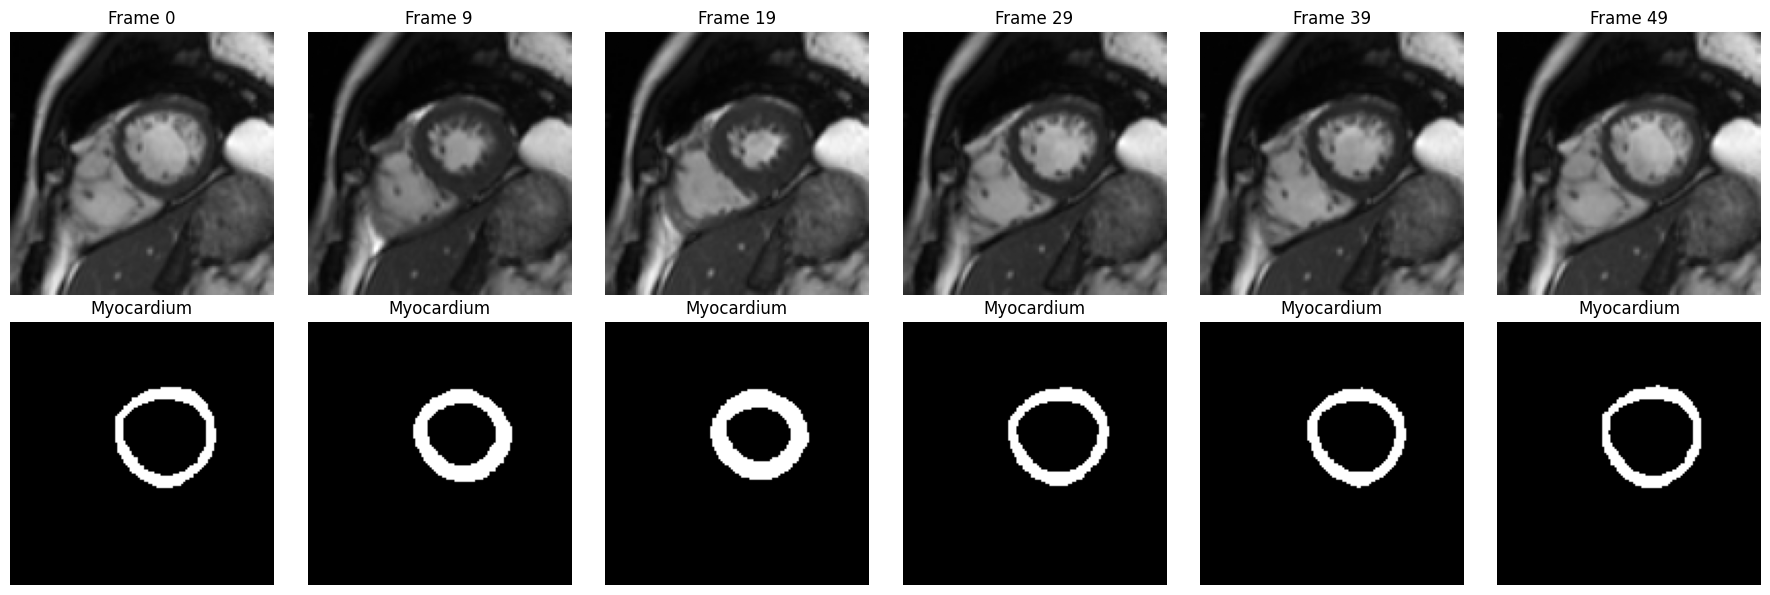

In [14]:
# Visualize segmentation
n_display = 6
frame_indices = np.linspace(0, n_frames-1, n_display, dtype=int)

fig, axes = plt.subplots(2, n_display, figsize=(3*n_display, 6))

for i, frame_idx in enumerate(frame_indices):
    axes[0, i].imshow(images_preprocessed[frame_idx], cmap='gray')
    axes[0, i].set_title(f'Frame {frame_idx}')
    axes[0, i].axis('off')
    
    axes[1, i].imshow(myocardium_mask[frame_idx], cmap='gray')
    axes[1, i].set_title('Myocardium')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=12)
axes[1, 0].set_ylabel('Segmentation', fontsize=12)
plt.tight_layout()
plt.show()

## 6. LaMoD Motion Tracking

Use the new simplified API for LaMoD motion tracking.

In [15]:
# Import the new LaMoD API
from cardiac_toolkit_to_be_organized.motion import lamod_displacement

print("LaMoD API imported successfully!")
print("\nThis will run the full 3-stage pipeline:")
print("  1. RegNet registration")
print("  2. Diffusion refinement")
print("  3. Motion decoder")

LaMoD API imported successfully!

This will run the full 3-stage pipeline:
  1. RegNet registration
  2. Diffusion refinement
  3. Motion decoder


In [16]:
# Run LaMoD displacement estimation
print("Running LaMoD inference...")
print("Note: This may take a few minutes for the full pipeline\n")

displacement = lamod_displacement(
    myocardium_mask,
    device='cuda',           # Use GPU acceleration
    skip_diffusion=False,    # Full quality with diffusion
    output_resolution=128,   # Match input resolution
    return_details=False     # Only return displacement
)

print(f"\nLaMoD inference complete!")
print(f"Displacement shape: {displacement.shape}")
print(f"  {displacement.shape[0]} displacement fields (T-1 frames)")
print(f"  Resolution: {displacement.shape[1]}x{displacement.shape[2]}")
print(f"  Components: dx, dy = {displacement.shape[3]}")

Running LaMoD inference...
Note: This may take a few minutes for the full pipeline

Skip connect: False
Loading pretrained model from /home/jx332/project/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit_to_be_organized/motion/tracking/lamod/checkpoints/ours_registration.pth
Unrecognized keyword argument: beta_schedule_overwrite = True
Unrecognized keyword argument: load_pretrained = True
Unrecognized keyword argument: pretrained_model_path = /home/jx332/project/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit_to_be_organized/motion/tracking/lamod/checkpoints/ours_latent_diffusion.pth
beta_schedule_method='linear'
Loading pretrained model from /home/jx332/project/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit_to_be_organized/motion/tracking/lamod/checkpoints/ours_latent_diffusion.pth


/home/jx332/project/.conda/LaMoD/lib/python3.10/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Overwriting beta schedule with linear schedule with scale 30
ignorekwargs: {'type': 'DiffusionDecoder', 'drouput': 0.3, 'load_pretrained': True, 'pretrained_model_path': '/home/jx332/project/code/2025-04-Cardiac-Img-Preprocessing-Toolkit/cardiac_toolkit_to_be_organized/motion/tracking/lamod/checkpoints/ours_motion_regression.pth'}
Decoder tanh_out:  False
Decoder: give_pre_end=False, tanh_out=False, out_scaling_factor=1
Working with z of shape (1, 16, 16, 16) = 4096 dimensions.
making attention of type 'vanilla' with 256 in_channels
making attention of type 'vanilla' with 256 in_channels
making attention of type 'vanilla' with 256 in_channels
making attention of type 'vanilla' with 256 in_channels
making attention of type 'vanilla' with 128 in_channels
making attention of type 'vanilla' with 128 in_channels
making attention of type 'vanilla' with 128 in_channels
making attention of type 'vanilla' with 64 in_channels
making attention of type 'vanilla' with 64 in_channels
making attentio

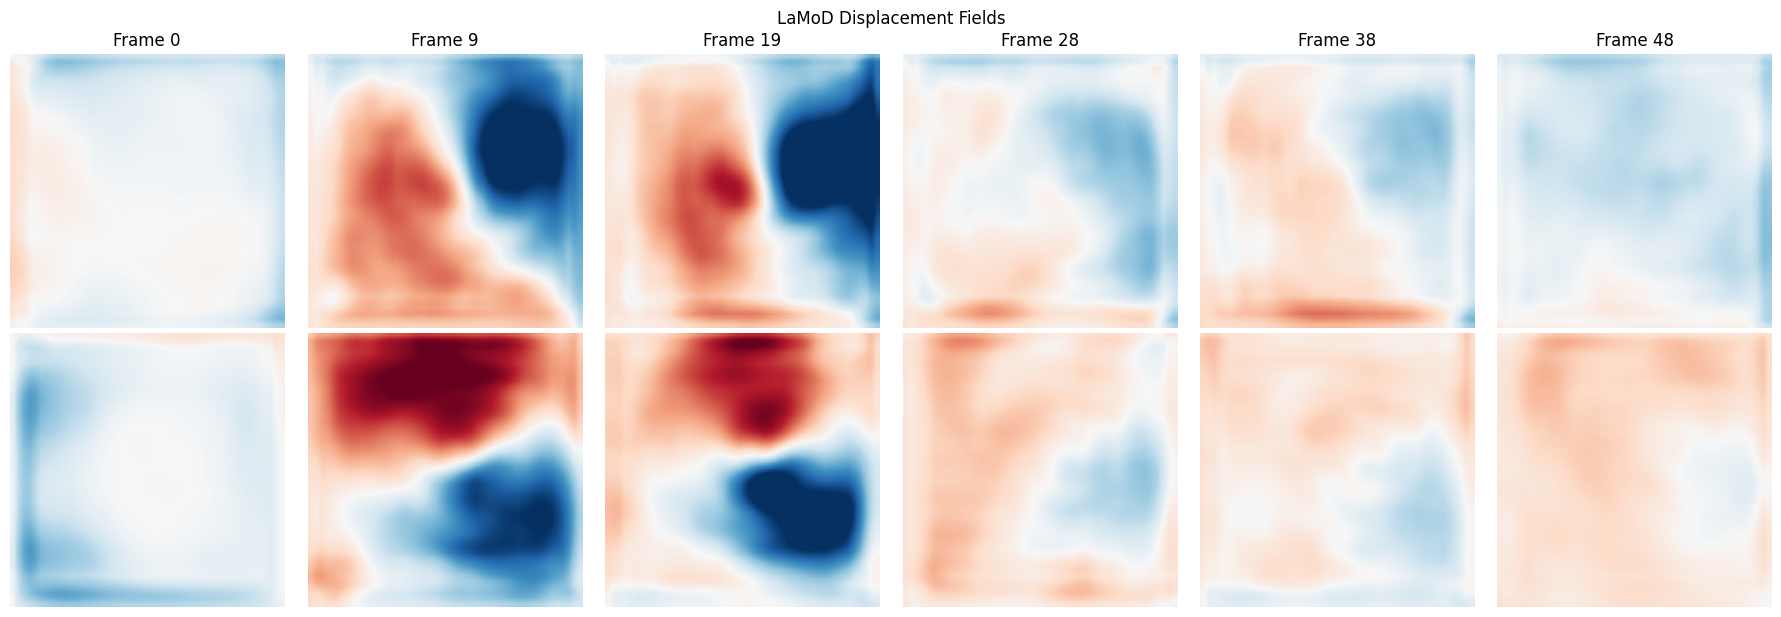

In [17]:
# Visualize displacement fields
n_disp_frames = displacement.shape[0]
n_display = 6
frame_indices = np.linspace(0, n_disp_frames-1, n_display, dtype=int)

fig, axes = plt.subplots(2, n_display, figsize=(3*n_display, 6))

for i, frame_idx in enumerate(frame_indices):
    # X displacement
    axes[0, i].imshow(displacement[frame_idx, :, :, 0], cmap='RdBu_r', vmin=-5, vmax=5)
    axes[0, i].set_title(f'Frame {frame_idx}')
    axes[0, i].axis('off')
    
    # Y displacement
    axes[1, i].imshow(displacement[frame_idx, :, :, 1], cmap='RdBu_r', vmin=-5, vmax=5)
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('X Displacement', fontsize=12)
axes[1, 0].set_ylabel('Y Displacement', fontsize=12)
plt.tight_layout()
plt.suptitle('LaMoD Displacement Fields', y=1.02)
plt.show()

## 7. Strain Analysis

In [18]:
# Compute strain from displacement
from modules.data.processing.strain_analysis.pixelstrain import pixelstrain

H, W = displacement.shape[1:3]
X, Y = np.meshgrid(np.arange(W), np.arange(H))

# Rearrange displacement: (T-1, H, W, 2) -> (H, W, T-1) for X and Y
dXt = displacement[:, :, :, 0].transpose(1, 2, 0)
dYt = displacement[:, :, :, 1].transpose(1, 2, 0)

# Use first frame mask
mask_128 = myocardium_mask[0].astype(bool)

print(f"Computing strain...")
Nfr = displacement.shape[0]
strain = pixelstrain(
    X=X, Y=Y,
    dXt=dXt, dYt=dYt,
    mask=mask_128,
    times=np.arange(Nfr)
)

print(f"Strain computed successfully!")
print(f"Available components: {list(strain.keys())}")

Computing strain...
Strain computed successfully!
Available components: ['vertices', 'faces', 'orientation', 'maskimage', 'XX', 'YY', 'XY', 'YX', 'RR', 'CC', 'RC', 'CR', 'p1', 'p2', 'p1or']


/tmp/ipykernel_3842526/2608238893.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


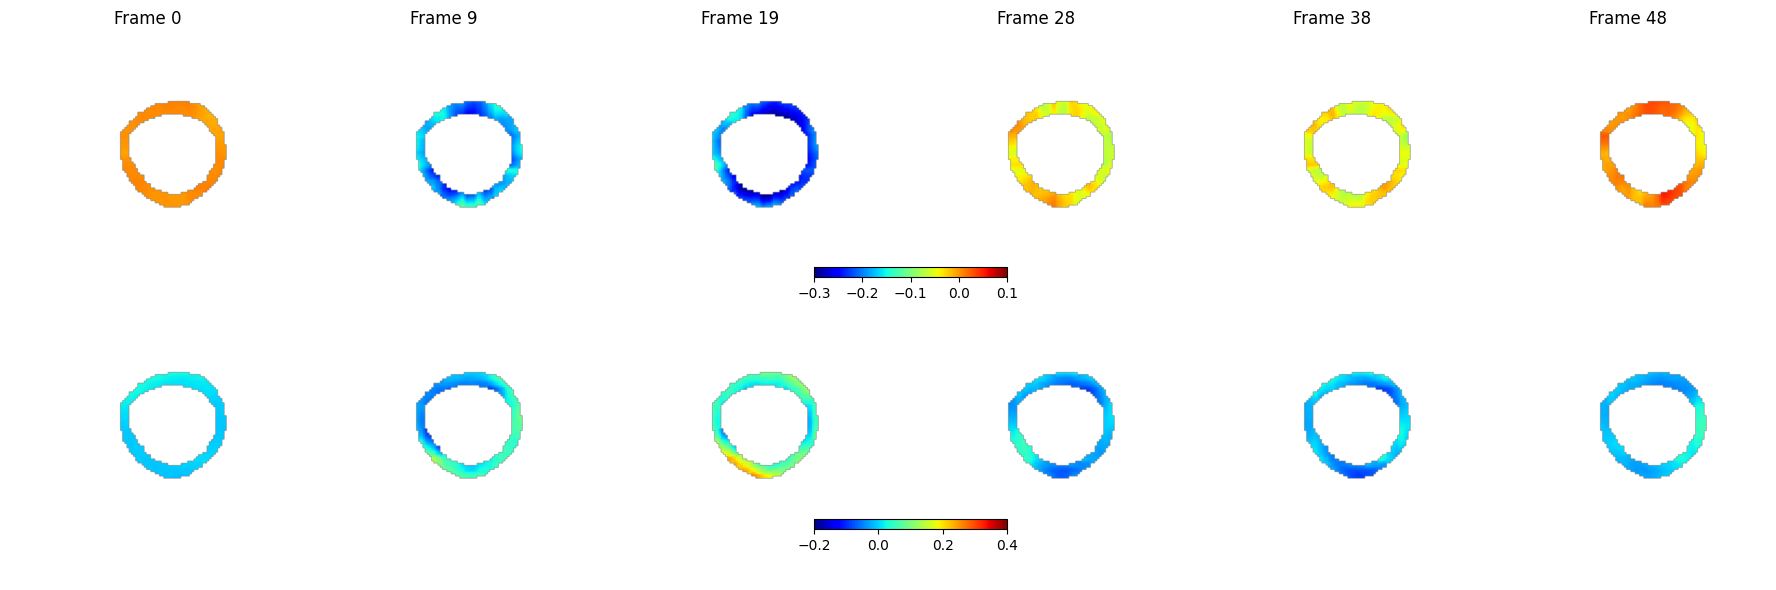

In [19]:
# Visualize strain maps
n_strain_frames = strain['CC'].shape[-1]
n_display = 6
frame_indices = np.linspace(0, n_strain_frames-1, n_display, dtype=int)

fig, axes = plt.subplots(2, n_display, figsize=(3*n_display, 6))

for i, frame_idx in enumerate(frame_indices):
    # Circumferential strain
    im1 = axes[0, i].imshow(strain['CC'][..., frame_idx], cmap='jet', vmin=-0.3, vmax=0.1)
    axes[0, i].set_title(f'Frame {frame_idx}')
    axes[0, i].axis('off')
    
    # Radial strain
    im2 = axes[1, i].imshow(strain['RR'][..., frame_idx], cmap='jet', vmin=-0.2, vmax=0.4)
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Circumferential\nStrain', fontsize=12)
axes[1, 0].set_ylabel('Radial\nStrain', fontsize=12)

plt.colorbar(im1, ax=axes[0, :], orientation='horizontal', pad=0.05, fraction=0.046)
plt.colorbar(im2, ax=axes[1, :], orientation='horizontal', pad=0.05, fraction=0.046)

plt.tight_layout()
plt.show()

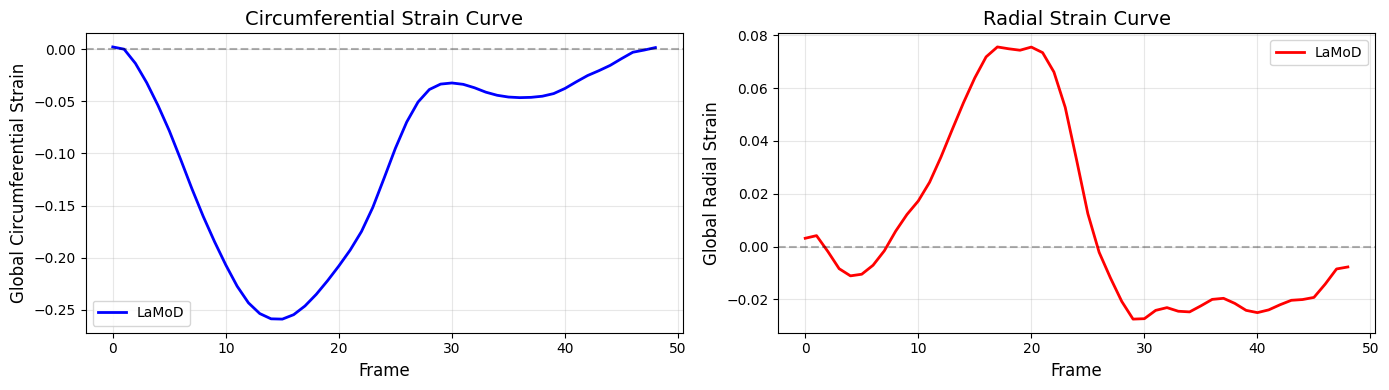

Peak Circumferential Strain: -0.2590
Peak Radial Strain: 0.0756


In [20]:
# Plot global strain curves
def compute_global_strain(strain_map, mask):
    """Compute mean strain over masked region for each time point"""
    n_frames = strain_map.shape[-1]
    global_strain = []
    
    for t in range(n_frames):
        frame_strain = strain_map[..., t]
        valid_strain = frame_strain[mask & ~np.isnan(frame_strain)]
        if len(valid_strain) > 0:
            global_strain.append(valid_strain.mean())
        else:
            global_strain.append(np.nan)
    
    return np.array(global_strain)

# Compute global strains
global_cc = compute_global_strain(strain['CC'], mask_128)
global_rr = compute_global_strain(strain['RR'], mask_128)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(global_cc, 'b-', linewidth=2, label='LaMoD')
axes[0].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[0].set_xlabel('Frame', fontsize=12)
axes[0].set_ylabel('Global Circumferential Strain', fontsize=12)
axes[0].set_title('Circumferential Strain Curve', fontsize=14)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(global_rr, 'r-', linewidth=2, label='LaMoD')
axes[1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1].set_xlabel('Frame', fontsize=12)
axes[1].set_ylabel('Global Radial Strain', fontsize=12)
axes[1].set_title('Radial Strain Curve', fontsize=14)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Peak Circumferential Strain: {np.nanmin(global_cc):.4f}")
print(f"Peak Radial Strain: {np.nanmax(global_rr):.4f}")

## Summary

This notebook successfully demonstrated:

1. ✓ Loading UK Biobank cardiac cine MRI data
2. ✓ Automatic whole heart detection and preprocessing
3. ✓ Myocardium segmentation with CarSON
4. ✓ **High-quality motion tracking with LaMoD** using the new simplified API
5. ✓ Comprehensive strain analysis

**Key Advantages of New API:**
- Single function call: `lamod_displacement()`
- Self-contained toolkit (no external imports)
- Clean, organized code structure
- Full diffusion refinement for highest quality

**Next Steps:**
- Try `skip_diffusion=True` for faster processing
- Compare with RegNet-only results (see RegNet example notebook)
- Process multiple subjects in batch